In [1]:
import numpy as np

def tanh(x):
    return np.tanh(x)


def tanh_der(a, z):
    return 1.0 - z * z


def sigmoid(x):
    x = np.asarray(x, dtype=float)
    e = np.exp(-np.abs(x))
    return np.where(x >= 0, 1.0 / (1.0 + e), e / (1.0 + e))


def sigmoid_der(a, z):
    return z * (1.0 - z)


def relu(x):
    return np.maximum(0.0, x)


def relu_der(a, z):
    return np.where(np.asarray(a) > 0, 1.0, 0.0)


def linear(x):
    return x


def linear_der(a, z):
    return np.ones_like(a, dtype=float)


ACTIVATIONS = {
    "tanh": (tanh, tanh_der),
    "sigmoid": (sigmoid, sigmoid_der),
    "relu": (relu, relu_der),
    "linear": (linear, linear_der),
}

def mse(y_pred, y_true):
    return np.mean((y_true - y_pred) ** 2)


def half_mse(y_pred, y_true):
    return 0.5 * mse(y_pred, y_true)


def half_mse_der(y_pred, y_true):
    return (y_pred - y_true) / y_pred.size


LOSS = {
    "half_mse": (half_mse, half_mse_der)
}

In [2]:
class Layer:
    def __init__(self, input_size, output_size, activation, rng):
        self.W = rng.normal(
            0,
            np.sqrt(1 / input_size),
            size=(output_size, input_size),
        )

        self.b = np.zeros(output_size)

        self.activation = activation

        self.input = None
        self.a = None
        self.z = None

        self.delta = None
        self.dW = None
        self.db = None


    def forward(self, z_prev):
        self.input = z_prev
        self.a = self.W @ z_prev + self.b
        self.z = self.activation(self.a)
        return self.z


class MLP:
    def __init__(
            self,
            input_size=1,
            hidden_sizes=None,
            hidden_activation="tanh",
            output_size=1,
            output_activation="linear",
            loss="half_mse",
            learning_rate=0.01,
            random_state=42,
            epochs=20,
    ):
        rng = np.random.default_rng(random_state)
        if hidden_sizes == None:
            hidden_sizes = []

        self.hidden_activation_func, self.hidden_activation_der = ACTIVATIONS[hidden_activation]
        self.output_activation_func, self.output_activation_der = ACTIVATIONS[output_activation]
        self.loss_fun, self.loss_der = LOSS[loss]
        self.lr = learning_rate
        self.epochs = epochs

        sizes = [input_size] + hidden_sizes + [output_size]
        self.layers = []
        for l in range(len(sizes) - 1):
            is_output = l == len(sizes) - 2
            activation = (
                self.output_activation_func
                if is_output
                else self.hidden_activation_func
            )

            layer = Layer(sizes[l], sizes[l + 1], activation, rng)
            self.layers.append(layer)


    def forward(self, x):
        z = x

        for layer in self.layers:
            z = layer.forward(z)

        return z


    def backward(self, y_pred, y_true):
        last_layer = self.layers[-1]

        last_layer.delta = self.loss_der(y_pred, y_true) * self.output_activation_der(last_layer.a, last_layer.z)
        last_layer.dW = np.outer(last_layer.delta, last_layer.input)
        last_layer.db = last_layer.delta.copy()

        for l in range(len(self.layers) - 2, -1, -1):
            current = self.layers[l]
            next_layer = self.layers[l + 1]

            current.delta = self.hidden_activation_der(current.a, current.z) * (next_layer.W.T @ next_layer.delta)
            current.dW = np.outer(current.delta, current.input)
            current.db = current.delta.copy()


    def step(self):
        for l in self.layers:
            l.W -= self.lr * l.dW
            l.b -= self.lr * l.db


    def fit(self, X, y, random_state=42, verbose=True):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        if X.ndim != 2 or X.shape[1] != self.layers[0].W.shape[1]:
            raise ValueError("X must have shape (n_samples, input_size)")
        if len(X) == 0:
            raise ValueError("Training data must not be empty")

        if y.ndim == 1:
            y = y.reshape(-1, 1)

        if y.shape != (len(X), self.layers[-1].W.shape[0]):
            raise ValueError("y must have shape (n_samples, output_size)")

        rng = np.random.default_rng(random_state)
        self.loss_history = []

        for epoch in range(self.epochs):
            for i in rng.permutation(len(X)):
                y_pred = self.forward(X[i])
                self.backward(y_pred, y[i])
                self.step()

            predictions = self.predict(X)
            loss = float(self.loss_fun(predictions, y))
            self.loss_history.append(loss)

            if verbose:
                print(f'Epoch {epoch + 1}/{self.epochs}, loss={loss:.6f}')

        return self


    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(1, -1)

        if X.ndim != 2 or X.shape[1] != self.layers[0].W.shape[1]:
            raise ValueError("X must have shape (n_samples, input_size)")
        if len(X) == 0:
            return np.empty((0, self.layers[-1].W.shape[0]))

        return np.stack([self.forward(x) for x in X])

## Первое обучение на функциях из задания 11

Для каждой из трёх функций создаём 100 точек на `[0, 1]` и добавляем нормальный шум со стандартным отклонением `0.1 * std(y_true)`. Размер выборки и уровень шума выбраны для первого эксперимента, в задании они не фиксированы.

Обучаем отдельную сеть для каждой функции, но используем одинаковую архитектуру `1 → 3 → 3 → 1`: два скрытых слоя с `tanh`, линейный выход, 3000 эпох, шаг обучения `0.01`. Это пробный запуск без подбора архитектуры и кросс-валидации.

In [3]:
import matplotlib.pyplot as plt

SEED = 42
N_SAMPLES = 100
NOISE_RATIO = 0.1
HIDDEN_SIZES = [3, 3]
EPOCHS = 3000
LEARNING_RATE = 0.01

FUNCTIONS = {
    'cos(2πx)': lambda x: np.cos(2 * np.pi * x),
    '5x³ + x² + 5': lambda x: 5 * x**3 + x**2 + 5,
    'x sin(2πx)': lambda x: x * np.sin(2 * np.pi * x),
}


def make_sample(function, n=N_SAMPLES, noise_ratio=NOISE_RATIO, seed=SEED):
    rng = np.random.default_rng(seed)
    x = np.sort(rng.uniform(0.0, 1.0, n))
    y_true = function(x)
    sigma = noise_ratio * np.std(y_true)
    y = y_true + rng.normal(0.0, sigma, n)
    return x.reshape(-1, 1), y.reshape(-1, 1), sigma


samples = {name: make_sample(function) for name, function in FUNCTIONS.items()}
x_grid = np.linspace(0.0, 1.0, 300).reshape(-1, 1)

In [4]:
models = {}
predictions = {}

for name, function in FUNCTIONS.items():
    X, y, sigma = samples[name]
    model = MLP(
        hidden_sizes=HIDDEN_SIZES,
        hidden_activation='tanh',
        output_activation='linear',
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS,
        random_state=SEED,
    )
    model.fit(X, y, random_state=SEED, verbose=False)
    models[name] = model
    predictions[name] = model.predict(x_grid)

    train_mse = mse(model.predict(X), y)
    grid_mse = mse(predictions[name], function(x_grid))
    print(f'{name}: σ={sigma:.4f}, train MSE={train_mse:.6f}, true grid MSE={grid_mse:.6f}')

cos(2πx): σ=0.0672, train MSE=0.004576, true grid MSE=0.000493
5x³ + x² + 5: σ=0.1504, train MSE=0.031199, true grid MSE=0.013933
x sin(2πx): σ=0.0389, train MSE=0.001857, true grid MSE=0.000636


`train MSE` показывает ошибку на зашумлённых обучающих точках. `true grid MSE` сравнивает предсказание с известной исходной функцией на плотной сетке без шума; это дополнительная оценка восстановления функции, а не кросс-валидация.

На нижних графиках показана функция потерь `0.5 * MSE` на обучающей выборке после каждой эпохи.

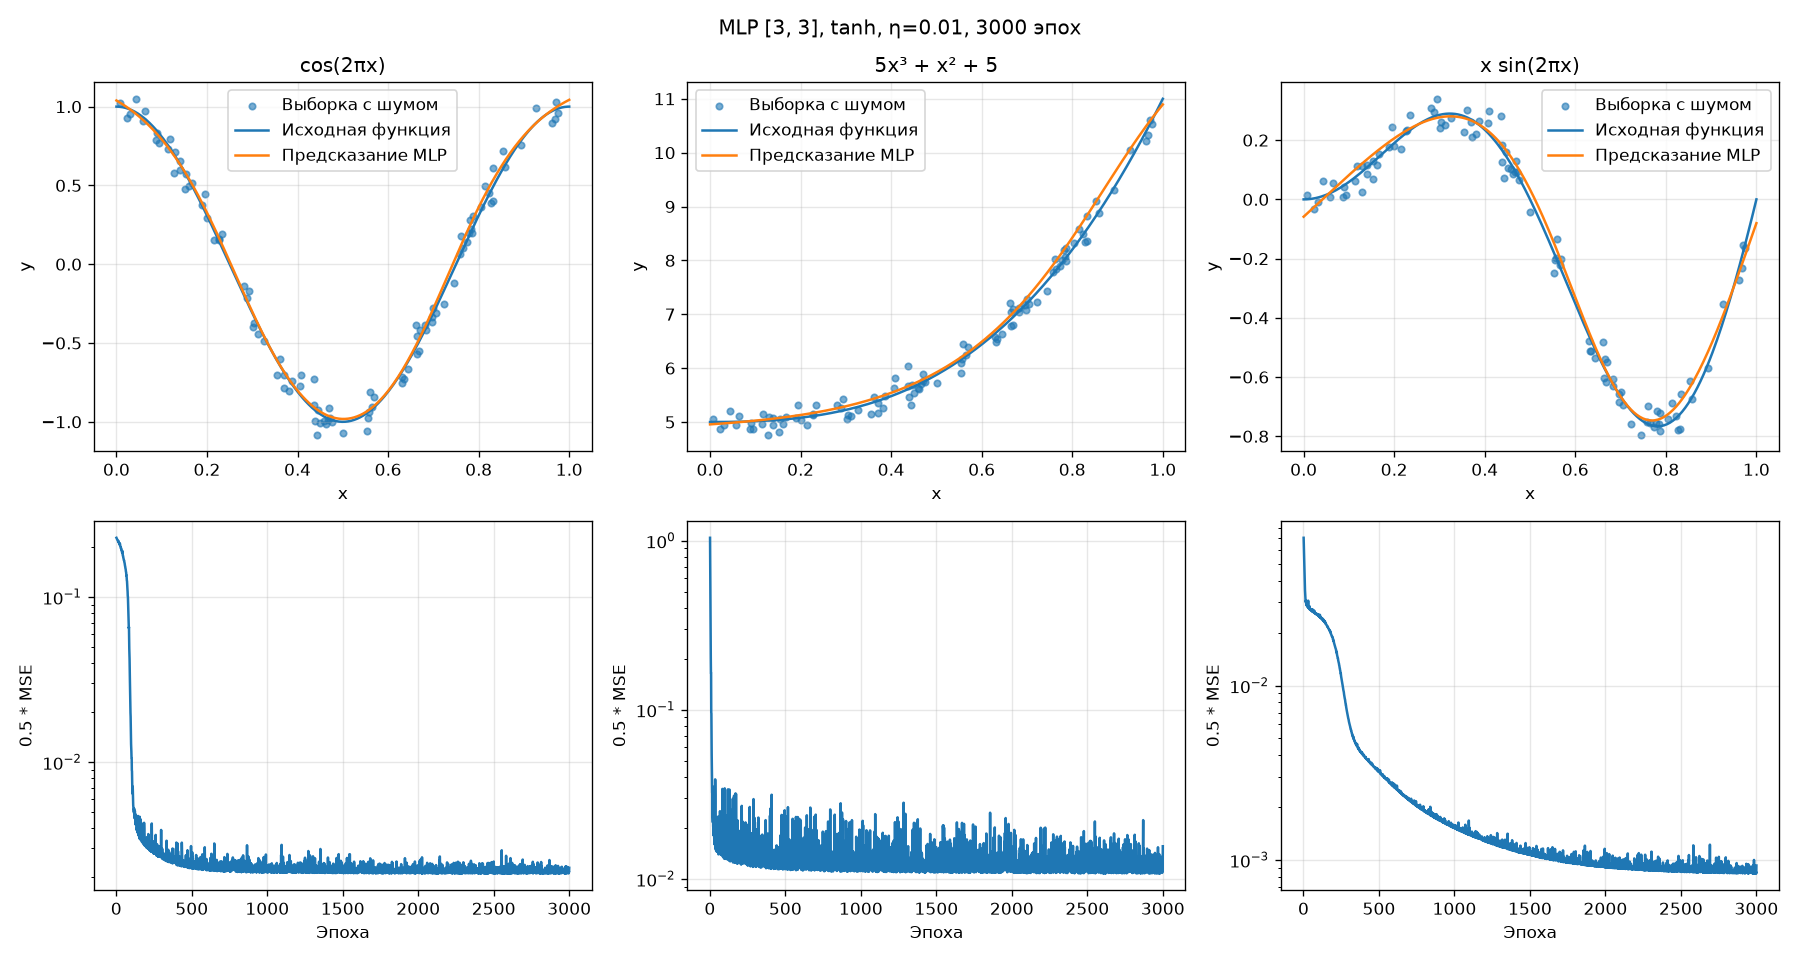

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for column, (name, function) in enumerate(FUNCTIONS.items()):
    X, y, sigma = samples[name]
    ax = axes[0, column]
    ax.scatter(X.ravel(), y.ravel(), s=15, alpha=0.6, label='Выборка с шумом')
    ax.plot(x_grid.ravel(), function(x_grid).ravel(), label='Исходная функция')
    ax.plot(x_grid.ravel(), predictions[name].ravel(), label='Предсказание MLP')
    ax.set(title=name, xlabel='x', ylabel='y')
    ax.legend()

    ax = axes[1, column]
    history = models[name].loss_history
    ax.plot(np.arange(1, len(history) + 1), history)
    ax.set(xlabel='Эпоха', ylabel='0.5 * MSE', yscale='log')

for ax in axes.flat:
    ax.grid(alpha=0.3)

fig.suptitle(f'MLP {HIDDEN_SIZES}, tanh, η={LEARNING_RATE}, {EPOCHS} эпох')
plt.tight_layout()
plt.show()